       X1  X2  X3  X4  X5  X6  X7  X8  X9  X10  ...    X15    X16    X17  \
0   20000   2   2   1  24   2   2  -1  -1   -2  ...      0      0      0   
1  120000   2   2   2  26  -1   2   0   0    0  ...   3272   3455   3261   
2   90000   2   2   2  34   0   0   0   0    0  ...  14331  14948  15549   
3   50000   2   2   1  37   0   0   0   0    0  ...  28314  28959  29547   
4   50000   1   2   1  57  -1   0  -1   0    0  ...  20940  19146  19131   

    X18    X19    X20   X21   X22   X23  Y  
0     0    689      0     0     0     0  1  
1     0   1000   1000  1000     0  2000  1  
2  1518   1500   1000  1000  1000  5000  0  
3  2000   2019   1200  1100  1069  1000  0  
4  2000  36681  10000  9000   689   679  0  

[5 rows x 24 columns]
(30000, 24)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   X1      30000 non-null  int64
 1   X2      30000 non-n

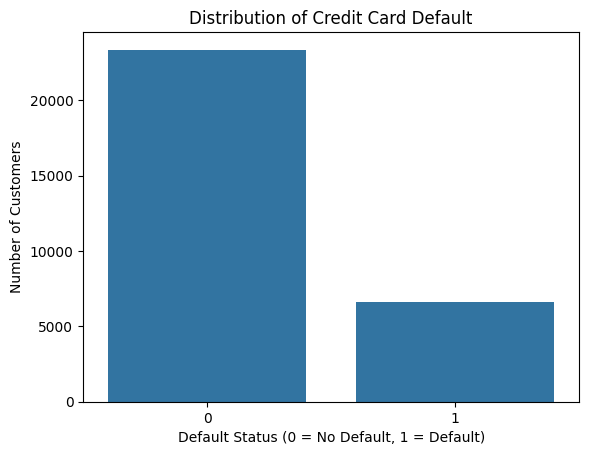

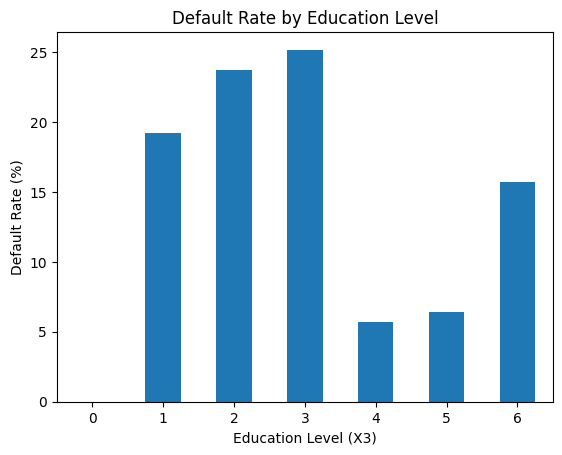

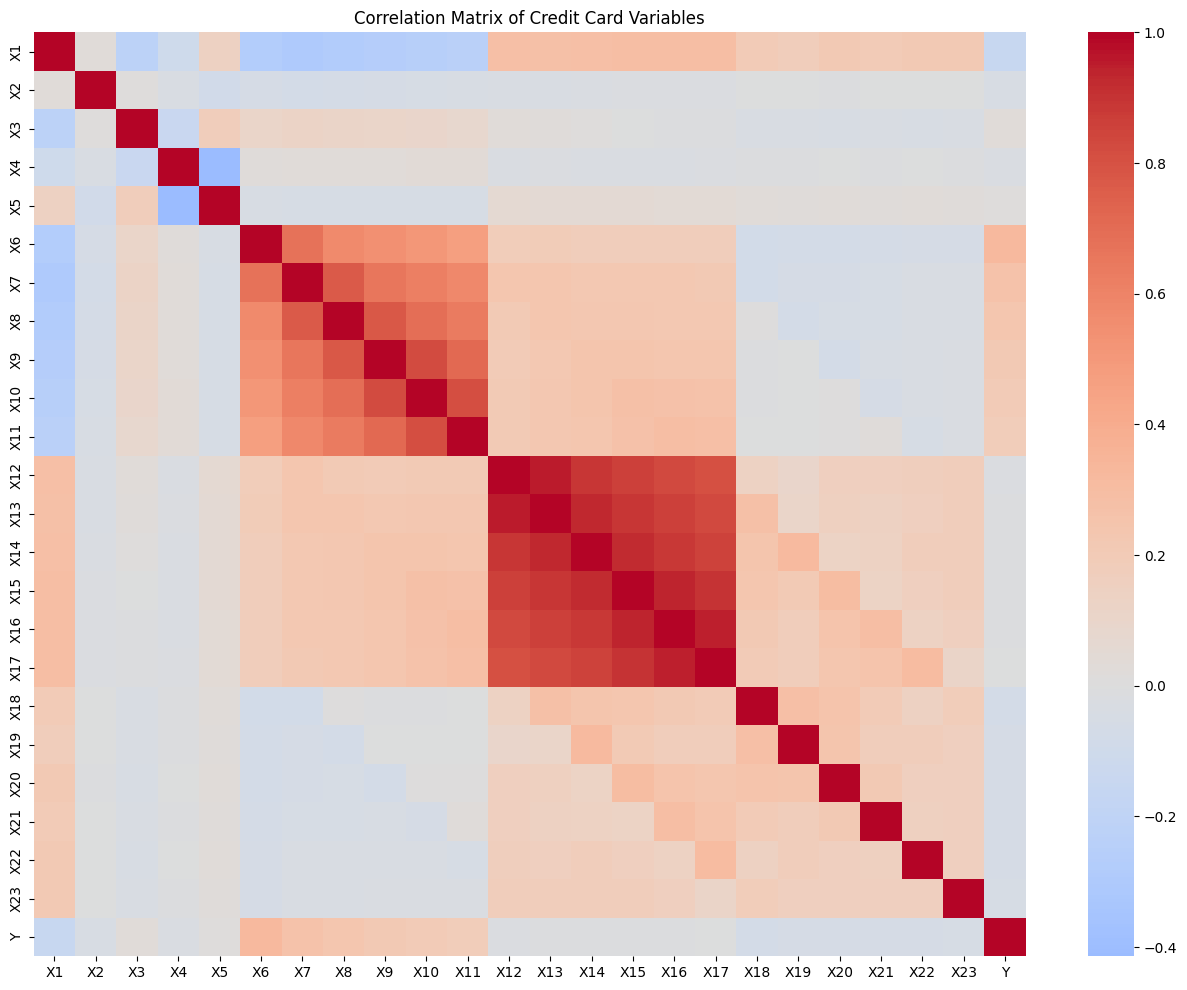

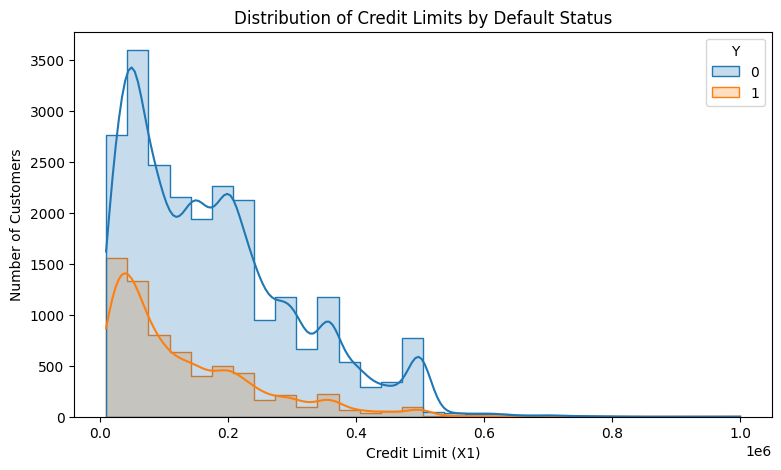

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
!pip install ucimlrepo pandas numpy matplotlib seaborn
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Fetch the dataset
credit_data = fetch_ucirepo(id=350)

# Separate features and target
X = credit_data.data.features
y = credit_data.data.targets

# Combine into one DataFrame
df = pd.concat([X, y], axis=1)

# Inspect the data
print(df.head()) #first 5 rows
print(df.shape)  #all rows in the dataset
print(df.info())

# Missing values
df.isnull().sum()

# Summary statistics
df.describe()

# Number of customers who defaulted
df["Y"].value_counts()

#GRAPHS

import matplotlib.pyplot as plt
import seaborn as sns

# Count customers in each default category
sns.countplot(data=df, x="Y")

# Add labels and title
plt.title("Distribution of Credit Card Default")
plt.xlabel("Default Status (0 = No Default, 1 = Default)")
plt.ylabel("Number of Customers")
plt.savefig(
    "default_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#default by education level (X3 is EDUCATION)
default_by_education = df.groupby("X3")["Y"].mean() * 100

default_by_education.plot(kind="bar")

plt.title("Default Rate by Education Level")
plt.xlabel("Education Level (X3)")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)
plt.savefig(
    "default_by_education.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

#correlation heatmaps
correlation = df.corr(numeric_only=True)

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Correlation Matrix of Credit Card Variables")
plt.show()

#distribution of credit limits (X1 is LIMIT_BAL)
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="X1",
    hue="Y",
    bins=30,
    kde=True,
    element="step"
)

plt.title("Distribution of Credit Limits by Default Status")
plt.xlabel("Credit Limit (X1)")
plt.ylabel("Number of Customers")
plt.savefig(
    "credit_limit_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

from google.colab import files

files.download("default_distribution.png")
files.download("default_by_education.png")
files.download("credit_limit_distribution.png")